Усі імпорти рекомендую розташувати отут зверху для зручності.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)

1.Завантажте дані у pandas dataframe з файла `ecommerce_data.csv`. Обовʼязково при завантаженні вкажіть параметр `encoding = 'ISO-8859-1'`, без нього буде помилка.

In [2]:
DATA_PATH = next(p for p in ['ecommerce_data_1.csv', 'ecommerce_data.csv', '../Матеріали/ecommerce_data_1.csv']
                 if os.path.exists(p))
df = pd.read_csv(DATA_PATH, encoding='ISO-8859-1')

2.Виведіть перші три записи в завантаженому наборі даних

In [3]:
df.head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom


3.Перейменуйте колонки, для цього просто запустіть код нижче та зверніть увагу, як ми перейменували колонки. Перейменування тут - просто для зручності.

In [4]:
df.rename(columns={'InvoiceNo': 'invoiceno', 'StockCode': 'stockcode', 'Description': 'description',
                   'Quantity': 'quantity', 'InvoiceDate': 'invoicedate', 'UnitPrice': 'unitprice',
                   'CustomerID': 'custid', 'Country': 'country'}, inplace=True)

4.Виведіть поточні назви колонок.

In [5]:
df.columns.tolist()

['invoiceno',
 'stockcode',
 'description',
 'quantity',
 'invoicedate',
 'unitprice',
 'custid',
 'country']

# Базове розуміння даних

5.Виведіть кількість колонок і стовпців в наборі даних.

In [6]:
print(f'Рядків: {df.shape[0]}, колонок: {df.shape[1]}')

Рядків: 541909, колонок: 8


6.Виведіть типи даних в кожній з колонок. Будь-яким способом, але аби для Вас як для дослідника стало зрозуміло, з якими даними ми зараз маємо справу.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   invoiceno    541909 non-null  object 
 1   stockcode    541909 non-null  object 
 2   description  540455 non-null  object 
 3   quantity     541909 non-null  int64  
 4   invoicedate  541909 non-null  object 
 5   unitprice    541909 non-null  float64
 6   custid       406829 non-null  float64
 7   country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


Очікуваний результат (один з):

![](https://drive.google.com/uc?export=view&id=1Pc2cam8vdZeEP4xLXlsoevOTt4O_KI4R)

7.Виведіть кількість пустих (null) значень в кожній з колонок за спаданням цієї кількості.

In [8]:
df.isnull().sum().sort_values(ascending=False)

custid         135080
description      1454
invoiceno           0
stockcode           0
quantity            0
invoicedate         0
unitprice           0
country             0
dtype: int64

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1IXVowBSH9-LtCR8gkMXcQHXWPinujkF5)

### Конвертація дат

8.Конвертуйте дату колонки `invoicedate` у тип `datetime64[ns]`.

In [9]:
df['invoicedate'] = pd.to_datetime(df['invoicedate'], format='%m/%d/%Y %H:%M')

Запустіть код нижче:

In [10]:
df.invoicedate[:2]

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
Name: invoicedate, dtype: datetime64[ns]

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1ds5CwdM5D50hlnk1zsDw7YT-aG_KErIg)

# Чистка даних

### Прибираємо пусті значення (NA)

9.Приберіть усі пусті значення з набору даних `df` і запишіть результат у нову змінну `df_new`.

In [11]:
df_new = df.dropna()

10.Виведіть кількість колонок і рядків в `df_new`.

In [12]:
print(f'Рядків: {df_new.shape[0]}, колонок: {df_new.shape[1]}')

Рядків: 406829, колонок: 8


11.Виведіть, який відсоток (від 0 до 100%) рядків ми видалили з `df`, коли прибрали пусті значення? Округліть результат до цілих відсотків.

In [13]:
removed_pct = (1 - len(df_new) / len(df)) * 100
print(f'{removed_pct:.0f}%')

25%


Очікуваний результат: `25%`

### Приберемо негативні значення `quantity`

12.Виведіть мінімальне, максимальне і середнє значення колонки `quantity`. Найкраще згадати, як це зробити одною командою, що дозволяє "описати" колонки в датафреймі :)

In [14]:
df_new.describe()

,quantity,invoicedate,unitprice,custid
count,406829.000000,406829,406829.000000,406829.000000
mean,12.061303,2011-07-10 16:30:57.879207424,3.460471,15287.690570
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13953.000000
50%,5.000000,2011-07-31 11:48:00,1.950000,15152.000000
75%,12.000000,2011-10-20 13:06:00,3.750000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,248.693370,NaN,69.315162,1713.600303


13.Скажімо, нас не цікавлять записи з негативними quantity (бо це поверненння).   
Приберіть всі рядки, де `quantity` менше 0 з набора даних `df_new` і запишіть в той самий набір даних `df_new`.

In [15]:
df_new = df_new[df_new['quantity'] >= 0].copy()
print(f'Лишилось рядків: {len(df_new)}')

Лишилось рядків: 397924


# Обробка даних

### Зміна типу даних `custid`

14.Ідентифікатор клієнта має мати тип "рядок" для простоти роботи з цією колонкою. Бо інакше пандас буде інтерпретувати цю колонку як число - а це логічно не правильно.
Перетворіть тип даних колонки `custid`  спочатку на int, а потім на рядок. Або можете зробити ці перетворення в одній функції (лямбді).

In [16]:
df_new['custid'] = df_new['custid'].astype(int).astype(str)

Запустіть код нижче:

In [17]:
df_new['custid'][:3]

0    17850
1    17850
2    17850
Name: custid, dtype: object

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1V5Mn0OC6hD-OmXGswe2N8CsIxsuBuoPE)

### Додамо колонку `amountspent`

15.Додайте в `df_new` колонку `amountspent`, яка є добутком колонок `quantity` і `unitprice`.

In [18]:
df_new['amountspent'] = df_new['quantity'] * df_new['unitprice']

### Додавання колонок `month`, `day`, `hour`, `yearmonth` для інвойса.

16.Використовуючи колонку invoicedate та те, що вона в нас вже має тип datetime, створіть 4 нових колонки в даних:
- `yearmonth` - рік і місяць інвойсу разом у форматі "2010-12" - тобто 12 місяць 2010го року і тип цієї колонки має бути датою (підказка: просто робимо для колонки`invoicedate` `dt.to_period('M')` для того аби таке отримати)
- `month` - місяць інвойсу
- `day` - день тижня інвойсу (понеділок - це перший, неділя - останній)
- `hour` - година інвойсу

Зробіть також так, аби `yearmonth` була третьою (за рахунком) колонкою в датафреймі, `month` - четвертою, `day` - пʼятою, `hour` - шостою.

In [19]:
df_new['yearmonth'] = df_new['invoicedate'].dt.to_period('M')
df_new['month'] = df_new['invoicedate'].dt.month
df_new['day'] = df_new['invoicedate'].dt.dayofweek + 1
df_new['hour'] = df_new['invoicedate'].dt.hour

new_cols = ['yearmonth', 'month', 'day', 'hour']
other_cols = [col for col in df_new.columns if col not in new_cols]
df_new = df_new[other_cols[:2] + new_cols + other_cols[2:]]

Запустіть код нижче:

In [20]:
df_new.head(3)

,invoiceno,stockcode,yearmonth,month,day,hour,description,quantity,invoicedate,unitprice,custid,country,amountspent
0,536365,85123A,2010-12,12,3,8,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,2010-12,12,3,8,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,2010-12,12,3,8,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00


In [21]:
df_new.dtypes

invoiceno              object
stockcode              object
yearmonth           period[M]
month                   int32
day                     int32
hour                    int32
description            object
quantity                int64
invoicedate    datetime64[ns]
unitprice             float64
custid                 object
country                object
amountspent           float64
dtype: object

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1Wn4tNmFOvqHk0VLpfwASKWiPpjJ5_Jgt)

![](https://drive.google.com/uc?export=view&id=1fYm7_uYhk14J51YkqJLtsQo_aqxz6jGZ)

# Базовий Exploratory Data Analysis (EDA)

17.Побудуйте з допомогою методів візуалізації `pandas` датафрейму (ті що з категорії `df.plot()`) стовпчастий графік кількості унікальних продажів помісячно за весь наявний період в даних. Зробіть так, аби підписи дат були нахилені під кутом 45 градусів для зручнішого перегляду.
Кількість унікальних продажів - це кількість унікальних інвойсів.

Підказка: для візуалізації нам спочатку треба агреугувати дані помісячно.

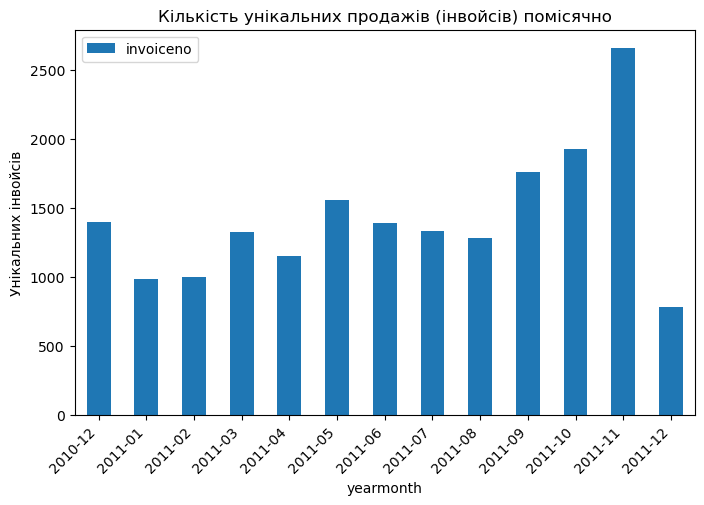

In [22]:
monthly_invoices = df_new.groupby('yearmonth')[['invoiceno']].nunique()
monthly_invoices.plot(kind='bar', figsize=(8, 5))
plt.title('Кількість унікальних продажів (інвойсів) помісячно')
plt.ylabel('Унікальних інвойсів')
plt.xticks(rotation=45, ha='right')
plt.show()

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1xbjqTCroVKLgdRxFGA9LG1T6Xx9eWlO1)

18.Побудуйте стовпчастий графік кількості унікальних інвойсів для топ 10 клієнтів за цим показником.

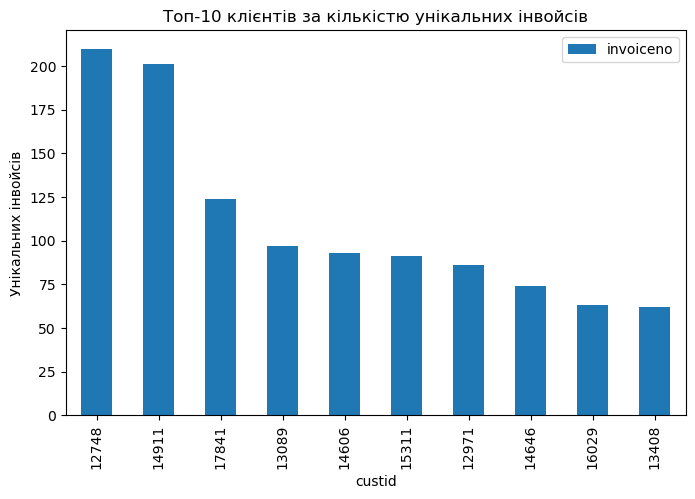

In [23]:
top_customers = (df_new.groupby('custid')[['invoiceno']].nunique()
                 .sort_values('invoiceno', ascending=False).head(10))
top_customers.plot(kind='bar', figsize=(8, 5))
plt.title('Топ-10 клієнтів за кількістю унікальних інвойсів')
plt.ylabel('Унікальних інвойсів')
plt.show()

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1zGhcVaPZBqcKj8YG_P-0pOzGVAV8cJNr)

19.Створіть новий датафрейм, що містить сумарний `amountspent` по кожному ідентифікатору клієнта.

In [24]:
customer_spent = df_new.groupby('custid', as_index=False)['amountspent'].sum()
customer_spent.head()

,custid,amountspent
0,12346,77183.60
1,12347,4310.00
2,12348,1797.24
3,12349,1757.55
4,12350,334.40


20.Використовуючи датафрейм з попереднього пункту, виведіть, якими є 10, 25, 50, 75 і 90 персентилі сумарних витрат клієнтів за розглянутий період:

In [25]:
customer_spent.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

,amountspent
count,4339.000000
mean,2053.793018
std,8988.248381
min,0.000000
10%,156.566000
25%,307.245000
50%,674.450000
75%,1661.640000
90%,3646.164000
max,280206.020000


Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=16h2lsEwR3GooNkzH0JLfJHRk5oyG3ZqE)

21.Скільки унікальних клієнтів мають сумарні витрати вищі, ніж 90-тий персентиль в попередньому завдані?

In [26]:
p90 = customer_spent['amountspent'].quantile(0.9)
top_spenders = customer_spent.loc[customer_spent['amountspent'] > p90, 'custid'].nunique()
print(f'90-й персентиль: {p90:,.2f}')
print(f'Клієнтів із витратами вище за нього: {top_spenders}')

90-й персентиль: 3,646.16
Клієнтів із витратами вище за нього: 434


22.Виведіть середню суму покупок в мережі по дням тижня. Дні тижня мають йти в звичному порядку Monday, Tuesday і т.д.

In [27]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
invoices = df_new.groupby('invoiceno').agg(amountspent=('amountspent', 'sum'), invoicedate=('invoicedate', 'first'))
invoices['weekday'] = pd.Categorical(invoices['invoicedate'].dt.day_name(), categories=weekday_order, ordered=True)

avg_by_weekday = invoices.groupby('weekday', observed=False)['amountspent'].agg(['mean', 'count']).round(2)
avg_by_weekday.columns = ['Середня сума інвойсу', 'Інвойсів']
avg_by_weekday

,Середня сума інвойсу,Інвойсів
weekday,,
Monday,477.52,2863
Tuesday,533.95,3185
Wednesday,459.72,3455
Thursday,490.17,4033
Friday,524.87,2831
Saturday,NaN,0
Sunday,365.38,2169


**Висновок.** Найбільша середня сума покупки — у вівторок (534) і пʼятницю (525), найменша — у неділю (365). Найбільше замовлень — у четвер (4 033). У суботу продажів немає зовсім: схоже, у суботу магазин замовлень не оформлює.

## Дослідимо продажі на суму 0 умовних одиниць

23.Можна було помітити вище, що в нас є продажі на суму 0. Дослідимо їх. Створіть новий датафрейм з тільки такими продажами.

In [28]:
zero_sales = df_new[df_new['amountspent'] == 0]
print(f'Рядків із сумою 0: {len(zero_sales)}, унікальних інвойсів: {zero_sales["invoiceno"].nunique()}')
zero_sales.head()

Рядків із сумою 0: 40, унікальних інвойсів: 34


,invoiceno,stockcode,yearmonth,month,day,hour,description,quantity,invoicedate,unitprice,custid,country,amountspent
9302,537197,22841,2010-12,12,7,14,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647,Germany,0.0
33576,539263,22580,2010-12,12,4,14,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560,United Kingdom,0.0
40089,539722,22423,2010-12,12,2,13,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911,EIRE,0.0
47068,540372,22090,2011-01,1,4,16,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081,United Kingdom,0.0
47070,540372,22553,2011-01,1,4,16,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081,United Kingdom,0.0


### Динаміка продажів на суму 0

24.Зобразіть у вигляді стовпчастої діаграми помісячну динаміку продажів на суму 0.

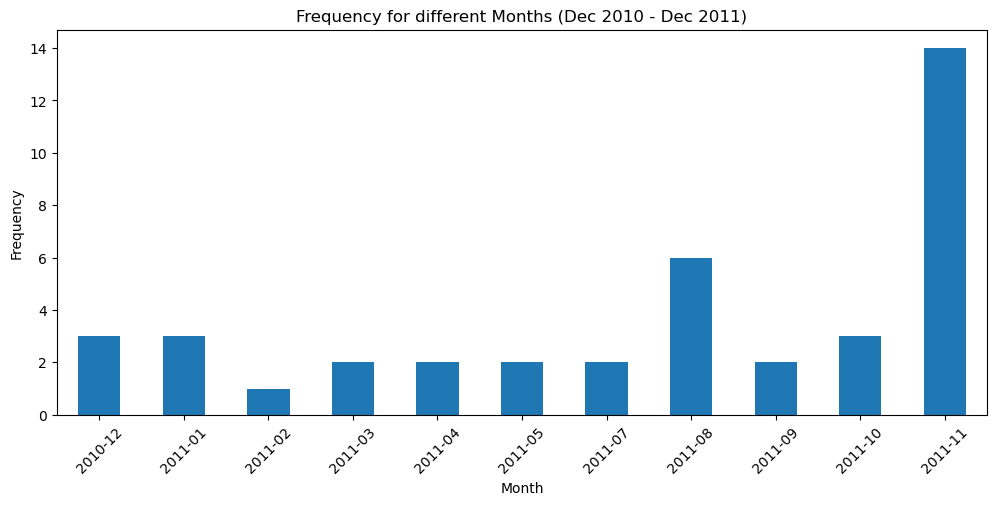

In [29]:
zero_monthly = zero_sales.groupby('yearmonth').size()
zero_monthly.plot(kind='bar', figsize=(12, 5))
plt.title('Frequency for different Months (Dec 2010 - Dec 2011)')
plt.xlabel('Month')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1RfpdWGqkOmwZ6RVUqQz-U-q3qkml5g88)

25.Згрупуйте дані за країнами та підрахуйте кількість унікальних інвойсів з сумою 0 для кожної країни. Виведіть у вигляді датафрейму.

In [30]:
zero_by_country = (zero_sales.groupby('country', as_index=False)['invoiceno'].nunique()
                   .rename(columns={'invoiceno': 'num_orders'})
                   .sort_values('num_orders', ascending=False))
zero_by_country

,country,num_orders
9,United Kingdom,21
0,Australia,3
1,EIRE,2
3,Germany,2
2,France,1
4,Netherlands,1
5,Norway,1
6,RSA,1
7,Spain,1
8,Switzerland,1


Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1N9rcWby_Umc31Q7e-1p2bCb1nCpzadoz)

Велике питання, чого магазин так багато порівняно роздавав безкоштовних товарів в UK, але така політика фірми :)

Якщо у вас ще є натхнення, пропоную задати до цих даних ще 3 своїх питання.

**Питання 1.** Які країни, крім Великої Британії, приносять найбільше виручки?

Частка Великої Британії у виручці: 82%


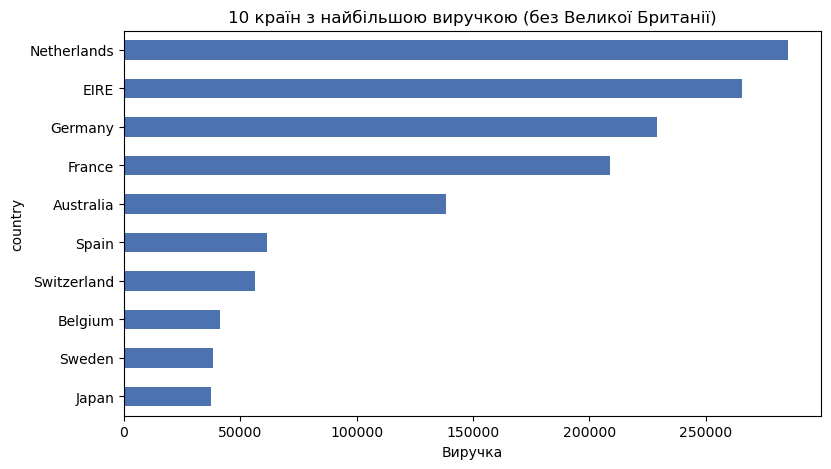

In [31]:
country_revenue = df_new.groupby('country')['amountspent'].sum().sort_values(ascending=False)
print(f"Частка Великої Британії у виручці: {country_revenue['United Kingdom'] / country_revenue.sum():.0%}")

country_revenue.drop('United Kingdom').head(10).sort_values().plot(kind='barh', figsize=(9, 5), color='#4C72B0')
plt.title('10 країн з найбільшою виручкою (без Великої Британії)')
plt.xlabel('Виручка')
plt.show()

**Відповідь.** Велика Британія дає 82 % виручки. Серед інших країн лідирують Нідерланди (близько 285 тис.), Ірландія (EIRE, 266 тис.), Німеччина (229 тис.) і Франція (209 тис.). Саме на ці ринки варто орієнтуватись, розвиваючи продажі за кордоном.

**Питання 2.** Які товари найпопулярніші за кількістю проданих одиниць і за виручкою?

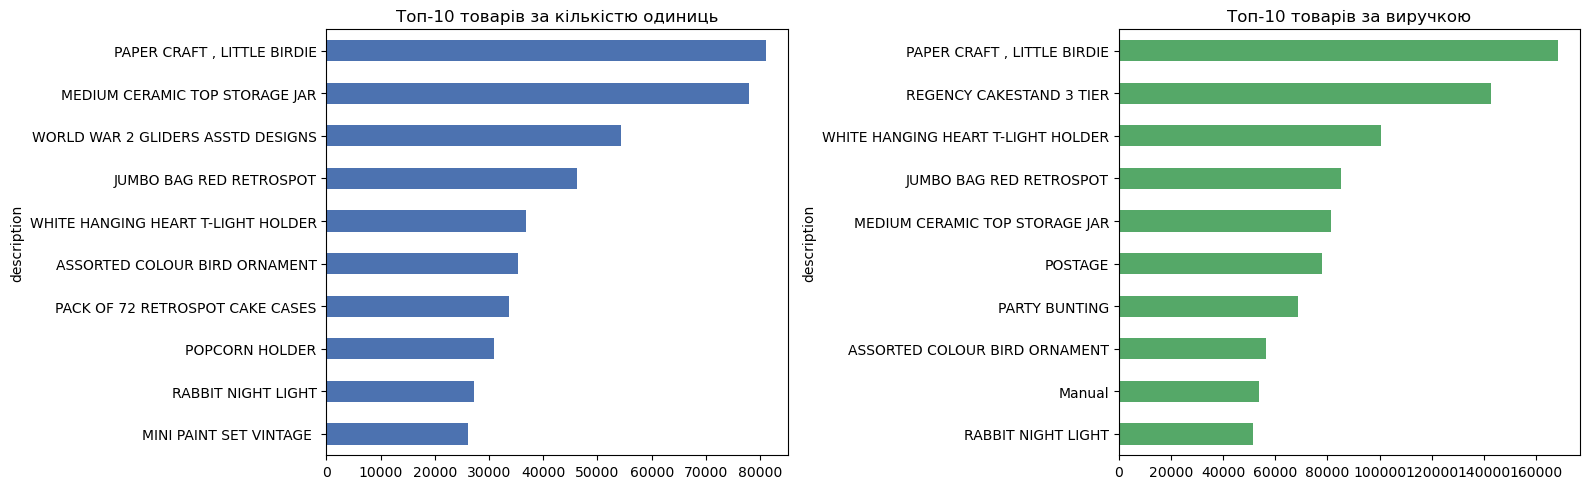

In [32]:
products = df_new.groupby('description').agg(units=('quantity', 'sum'), revenue=('amountspent', 'sum'))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
products['units'].nlargest(10).sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_title('Топ-10 товарів за кількістю одиниць')
products['revenue'].nlargest(10).sort_values().plot(kind='barh', ax=axes[1], color='#55A868')
axes[1].set_title('Топ-10 товарів за виручкою')
plt.tight_layout()
plt.show()

**Відповідь.** За кількістю одиниць формально лідирують `PAPER CRAFT , LITTLE BIRDIE` (80 995) і `MEDIUM CERAMIC TOP STORAGE JAR` (77 916). Але це наслідок двох гуртових замовлень на 80 995 і 74 215 штук. У вихідних даних обидва скасовані поверненням через 12–16 хвилин, а ми прибрали лише повернення (`quantity < 0`), тож самі замовлення лишились. Стабільні лідери за одиницями — `WORLD WAR 2 GLIDERS ASSTD DESIGNS`, `JUMBO BAG RED RETROSPOT` і `WHITE HANGING HEART T-LIGHT HOLDER`. За виручкою (без скасованого замовлення) — `REGENCY CAKESTAND 3 TIER` (близько 143 тис.) і `WHITE HANGING HEART T-LIGHT HOLDER` (100 тис.).

**Висновок для чистки даних:** прибираючи повернення, треба прибирати і скасовані ними покупки. Інакше спотворюються рейтинги товарів і клієнтів: наприклад, усі витрати клієнта 12346 (77 183.60) — це саме скасоване замовлення.

**Питання 3.** О котрій годині й у які дні клієнти найчастіше оформлюють замовлення?

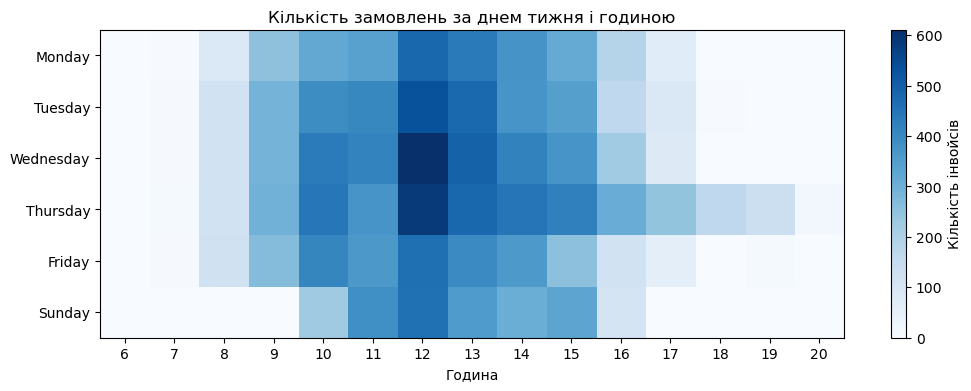

In [33]:
orders = df_new.drop_duplicates('invoiceno')
heatmap_data = (orders.groupby([orders['invoicedate'].dt.day_name(), 'hour'])['invoiceno'].count()
                .unstack(fill_value=0).reindex([d for d in weekday_order if d in orders['invoicedate'].dt.day_name().unique()]))

plt.figure(figsize=(12, 4))
plt.imshow(heatmap_data, aspect='auto', cmap='Blues')
plt.colorbar(label='Кількість інвойсів')
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
plt.xlabel('Година')
plt.title('Кількість замовлень за днем тижня і годиною')
plt.show()

**Відповідь.** Замовлення оформлюють у робочий час: майже всі — з 8:00 до 17:00, пік — опівдні (о 12:00 — 3 129 інвойсів). Найактивніший день — четвер, найменш активний — неділя, у суботу замовлень немає. Отже, підтримку клієнтів і розсилки варто планувати на першу половину дня в будні.